# IMPORTS

In [ ]:
# === 1. SETUP ===
import os, sys, importlib, json, csv
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

# utils path
sys.path.append(os.path.abspath(os.path.join("..")))

# helper modules -  reload in case of edits
import utils.eda_helpers as eda_helpers
import utils.helpers as helpers
importlib.reload(eda_helpers)
importlib.reload(helpers)
from utils.eda_helpers import *
from pathlib import Path
sys.path.append(os.path.join(os.getcwd(), '..'))
from utils.helpers import convert_to_serializable, save_json, load_csv_data_streamed, load_csv_data
from utils.eda_helpers import clean_data  # Henrik's cleaning function

# --- Define data folder ---
file_path = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_FOLDER = os.path.join(file_path, '..', 'dataset')

# Random seed
np.random.seed(42)

In [5]:
BASE_DIR = Path.cwd().resolve().parent
PLOTS_DIR = BASE_DIR / "plots" / "eda"
RESULTS_DIR = BASE_DIR / "results" / "eda"

for path in [PLOTS_DIR, RESULTS_DIR]:
    path.mkdir(parents=True, exist_ok=True)

print(f"Plots directory: {PLOTS_DIR}")
print(f"Results directory: {RESULTS_DIR}")


Plots directory: C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda
Results directory: C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda


In [6]:
def read_csv_numeric(path):
    # 1) read header for the name→index mapping
    with open(path, newline='', encoding='utf-8') as f:
        reader = csv.reader(f)
        header = next(reader)
    col_idx = {name: i for i, name in enumerate(header)}

    # 2) load the rest as a 2D float array (missing -> NaN)
    # reopen so the file pointer is at the top again
    data = np.genfromtxt(
        path,
        delimiter=",",
        skip_header=1,
        dtype=float,
        missing_values=["", "NA", "NaN"],
        filling_values=np.nan
    )
    # If the CSV has only one data row, genfromtxt returns 1D; force 2D
    if data.ndim == 1:
        data = data.reshape(1, -1)

    return col_idx, data

In [7]:
x_indices, x_data = read_csv_numeric("../dataset/x_train.csv")
y_indices, y_data = read_csv_numeric("../dataset/y_train.csv")

In [8]:
print(f"x_train shape: {x_data.shape}")
print(f"y_train shape: {y_data.shape}")
print(f"Example features: {list(x_indices)[:5]}")

x_train shape: (328135, 322)
y_train shape: (328135, 2)
Example features: ['Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH']


In [10]:
del x_indices["Id"]
x_data_clean = clean_data(x_data, x_indices)
print("Cleaned data shape:", x_data_clean.shape)

Cleaned data shape: (328135, 322)


# 1. Basic EDA
Descriptive statistics about the dataset.

In [11]:
x_train = x_data_clean
y_train = y_data[:, 1] if y_data.ndim > 1 else y_data
feature_names = list(x_indices.keys())
save_dir = RESULTS_DIR
plots_dir = PLOTS_DIR

### Size dataset

In [12]:
n, d = x_train.shape
print("Number of samples:", n)
print("Number of features:", d)
print("\ny distribution:", np.unique(y_train, return_counts=True))
print("Estimated memory (MB):", x_train.nbytes/1e6)
print("Data type:", x_train.dtype)

Number of samples: 328135
Number of features: 322

y distribution: (array([-1.,  1.]), array([299160,  28975]))
Estimated memory (MB): 845.27576
Data type: float64


### Features descriptive statistics

In [13]:
with open(os.path.join("..", "dataset", "x_train.csv"), "r") as f:
    reader = csv.reader(f)
    header = next(reader)  # first line = column names
feature_names = header[1:]  # exclude ID column
feature_names[:20]

['_STATE',
 'FMONTH',
 'IDATE',
 'IMONTH',
 'IDAY',
 'IYEAR',
 'DISPCODE',
 'SEQNO',
 '_PSU',
 'CTELENUM',
 'PVTRESD1',
 'COLGHOUS',
 'STATERES',
 'CELLFON3',
 'LADULT',
 'NUMADULT',
 'NUMMEN',
 'NUMWOMEN',
 'CTELNUM1',
 'CELLFON2']

In [16]:
summary_extended = dataset_describe(
    x_data_clean,
    feature_names=list(x_indices.keys()),
    max_features=20
)



Dataset shape: 328,135 samples × 322 features
 Idx |            Name |       Type |  Unique |  Missing |  %Miss |         Mean |          Std |          Min |          Max
-----------------------------------------------------------------------------------------------------------------------------
   0 | _STATE          | continuous |  328135 |        0 |   0.00 |     1.64e+05 |     9.47e+04 |            0 |     3.28e+05
   1 | FMONTH          | continuous |      53 |        0 |   0.00 |           30 |           16 |            1 |           72
   2 | IDATE           | continuous |      12 |        0 |   0.00 |         6.36 |         3.49 |            1 |           12
   3 | IMONTH          | continuous |     414 |        0 |   0.00 |     6.56e+06 |     3.49e+06 |     1.01e+06 |     1.23e+07
   4 | IDAY            | continuous |      12 |        0 |   0.00 |         6.42 |         3.49 |            1 |           12
   5 | IYEAR           | continuous |      31 |        0 |   0.00 |    

In [20]:
# print extended summary
for f in summary_extended[:2]:
    print(f"\nFeature {f['index']}: {f['name']}")
    for k, v in f.items():
        if k not in ['index', 'name']:
            print(f"  {k}: {v}")


Feature 0: _STATE
  type: continuous
  n_unique: 328135
  missing: 0
  missing_pct: 0.0
  mean: 164067.0
  std: 94724.41528982905
  min: 0.0
  max: 328134.0

Feature 1: FMONTH
  type: continuous
  n_unique: 53
  missing: 0
  missing_pct: 0.0
  mean: 29.973651088728726
  std: 16.031752874847626
  min: 1.0
  max: 72.0


### Missing values

In [21]:
n = x_train.shape[0]
missing_per_feature = np.isnan(x_train).sum(axis=0)
missing_ratio = missing_per_feature / n * 100

In [22]:
# global summary ab missing values
missing_summary = {
    "total_missing": int(np.isnan(x_train).sum()),
    "mean_missing_pct": float(np.mean(missing_ratio)),
    "median_missing_pct": float(np.median(missing_ratio)),
    "max_missing_pct": float(np.max(missing_ratio)),
    "n_features_missing": int(np.sum(missing_per_feature > 0)),
}
save_json(missing_summary, "missing_summary", save_dir=save_dir)

Saved missing_summary.json to C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\missing_summary.json


In [23]:
# per-feature summary
missing_features_summary = [
    {"index": i, "name": feature_names[i], "missing_count": int(missing_per_feature[i]), "missing_pct": float(missing_ratio[i])}
    for i in range(len(feature_names))
]
save_json(missing_features_summary, "missing_features_summary", save_dir=save_dir)

Saved missing_features_summary.json to C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\missing_features_summary.json


In [24]:
# print
print(f"\nTotal missing values: {missing_summary['total_missing']:,}")
print(f"Average missing per feature: {missing_summary['mean_missing_pct']:.3f}%")
print(f"Features with any missing values: {missing_summary['n_features_missing']} / {len(feature_names)}")
print(f"Max missing percentage: {missing_summary['max_missing_pct']:.2f}% ({feature_names[np.argmax(missing_ratio)]})")


Total missing values: 48,736,658
Average missing per feature: 46.126%
Features with any missing values: 289 / 321
Max missing percentage: 99.99% (STATERES)


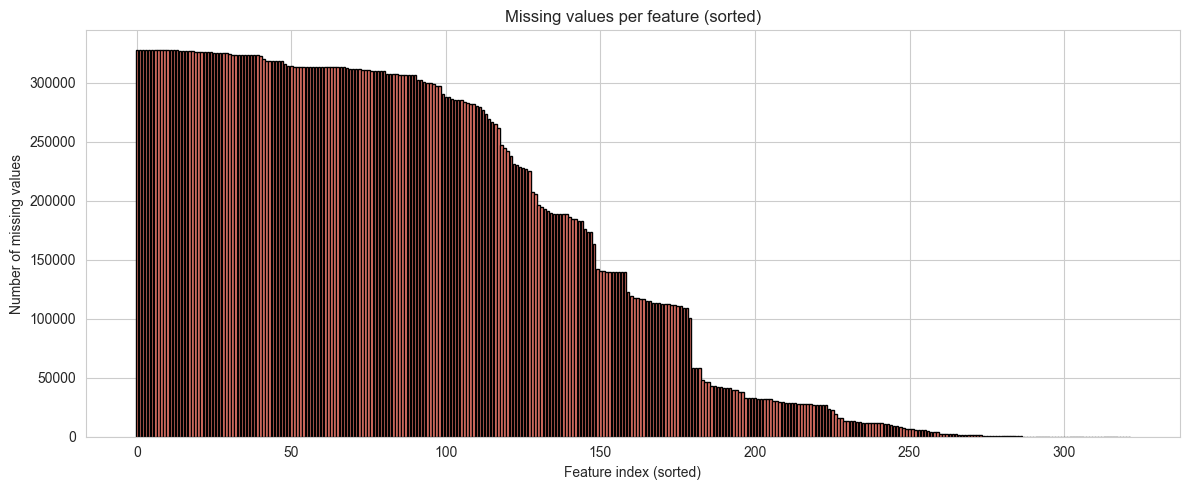

Saved sorted missing-values plot to C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\missing_values_sorted.png


In [40]:
# === Missing values visualization (sorted descending, by index) ===
n_missing = np.sum(np.isnan(x_data_clean), axis=0)

# sort descending
sorted_idx = np.argsort(n_missing)[::-1]
sorted_missing = n_missing[sorted_idx]

plt.figure(figsize=(12, 5))
plt.bar(range(len(sorted_missing)), sorted_missing, color="salmon", edgecolor="black")
plt.xlabel("Feature index (sorted)")
plt.ylabel("Number of missing values")
plt.title("Missing values per feature (sorted)")
plt.tight_layout()

save_path = PLOTS_DIR / "missing_values_sorted.png"
plt.savefig(save_path, bbox_inches="tight")
plt.show()

print(f"Saved sorted missing-values plot to {save_path}")


### Feature distribution analysis

In [45]:
# basic distribution metrics 
means = np.nanmean(x_train, axis=0)
stds = np.nanstd(x_train, axis=0)

# manual skewness and kurtosis
def compute_skew(x):
    x = x[~np.isnan(x)]
    if len(x) < 3:
        return np.nan
    m = np.mean(x)
    s = np.std(x)
    if s == 0:
        return np.nan  # constant feature
    return np.mean(((x - m) / s) ** 3)

def compute_kurtosis(x):
    x = x[~np.isnan(x)]
    if len(x) < 4:
        return np.nan
    m = np.mean(x)
    s = np.std(x)
    if s == 0:
        return np.nan  # constant feature
    return np.mean(((x - m) / s) ** 4)


skews = np.array([compute_skew(x_train[:, i]) for i in range(x_train.shape[1])])
kurtoses = np.array([compute_kurtosis(x_train[:, i]) for i in range(x_train.shape[1])])

print(f"Average std across features: {np.nanmean(stds):.3f}")
print(f"Highly skewed features (|skew| > 2): {np.sum(np.abs(skews) > 2)}")
print(f"Heavy-tailed features (kurtosis > 3): {np.sum(kurtoses > 3)}")

Average std across features: 12846.761
Highly skewed features (|skew| > 2): 132
Heavy-tailed features (kurtosis > 3): 192


In [48]:
# --- Reverse index mapping for real feature names ---
idx_to_feature = {v: k for k, v in x_indices.items()}

# --- Identify interesting features ---
high_skew_idx = np.argsort(np.abs(skews))[::-1]
heavy_tail_idx = np.argsort(kurtoses)[::-1]
most_variable_idx = np.argsort(stds)[::-1]

# Combine and filter NaN or constant columns
interesting_idx = []
for i in (list(high_skew_idx) + list(heavy_tail_idx) + list(most_variable_idx)):
    if i not in interesting_idx and not np.isnan(skews[i]) and not np.isnan(kurtoses[i]) and stds[i] > 0:
        interesting_idx.append(i)
    if len(interesting_idx) >= 10:  # pick top 10 meaningful features
        break

# --- Print summary ---
print("\nInteresting features (non-constant, meaningful stats):")
for i in interesting_idx:
    name = idx_to_feature.get(i, f"feature_{i}")
    print(f"  {name:<15} | skew={skews[i]:6.2f} | kurt={kurtoses[i]:6.2f} | std={stds[i]:10.2f}")



Interesting features (non-constant, meaningful stats):
  _VEG23          | skew=-91.71 | kurt=8411.72 | std=      0.01
  PVTRESD1        | skew= 76.78 | kurt=5895.50 | std=      0.01
  _FRT16          | skew=-68.44 | kurt=4685.64 | std=      0.01
  BEANDAY_        | skew= 66.59 | kurt=12632.92 | std=      0.48
  ORNGDAY_        | skew= 64.81 | kurt=12186.99 | std=      0.48
  VEGEDA1_        | skew= 38.17 | kurt=4152.38 | std=      0.81
  FTJUDA1_        | skew= 37.23 | kurt=4440.07 | std=      0.71
  GRENDAY_        | skew= 33.00 | kurt=3988.06 | std=      0.68
  _MINAC21        | skew= 29.33 | kurt=2625.43 | std=    363.93
  _VEGESUM        | skew= 27.28 | kurt=2521.24 | std=      1.57


In [ ]:
# === Visualize selected features (log scaling if needed) ===
hist_dir = os.path.join(plots_dir, "histograms", "high-skew-or-heavy-tail")
box_dir = os.path.join(plots_dir, "boxplots", "high-skew-or-heavy-tail")
os.makedirs(hist_dir, exist_ok=True)
os.makedirs(box_dir, exist_ok=True)

for i in interesting_idx:
    feat = x_train[:, i]
    feat = feat[~np.isnan(feat)]

    # Get real name from x_indices mapping
    name = next((k for k, v in x_indices.items() if v == i), f"feature_{i}")

    # Decide whether to log-transform
    use_log = False
    if np.all(feat > 0) and np.abs(skews[i]) > 2:
        use_log = True
        feat = np.log1p(feat)  # log(1 + x) avoids log(0) issues)

    # Histogram
    plt.figure(figsize=(5, 3))
    counts, bins = np.histogram(feat, bins=30, density=True)
    centers = 0.5 * (bins[1:] + bins[:-1])
    plt.bar(centers, counts, width=np.diff(bins), color="steelblue", alpha=0.6, edgecolor="black")
    plt.plot(centers, counts, color="black", linewidth=1.2)

    title_suffix = " (log-scale)" if use_log else ""
    plt.title(f"Distribution of {name}{title_suffix}")
    plt.xlabel(name)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.savefig(os.path.join(hist_dir, f"{name}_hist.png"), bbox_inches="tight")
    plt.close()

    # Boxplot
    plt.figure(figsize=(4, 2))
    plt.boxplot(feat, vert=True, patch_artist=True, boxprops=dict(facecolor="lightgray"))
    plt.title(f"Boxplot of {name}{title_suffix}")
    plt.tight_layout()
    plt.savefig(os.path.join(box_dir, f"{name}_box.png"), bbox_inches="tight")
    plt.close()

print(f"\nSaved histogram and boxplot visualizations for {len(interesting_idx)} interesting features.")


Saved histogram and boxplot visualizations for 10 interesting features.


### Target distribution (class balance)

Target distribution summary:
----------------------------------------
Class  -1:   299160 samples (91.17%)
Class   1:    28975 samples ( 8.83%)
----------------------------------------
Total samples: 328135



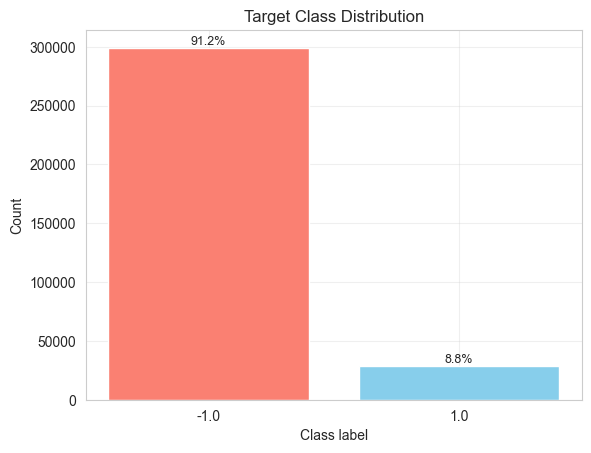

Saved target_summary.json to c:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\results\eda\target_summary.json


In [51]:
classes, counts = np.unique(y_train, return_counts=True)
total = np.sum(counts)
percentages = counts / total * 100

print("Target distribution summary:")
print("-" * 40)
for c, n, p in zip(classes, counts, percentages):
    print(f"Class {int(c):>3}: {n:>8} samples ({p:5.2f}%)")
print("-" * 40)
print(f"Total samples: {total}\n")

# plot class balance
plt.bar(classes.astype(str), counts, color=["salmon", "skyblue"])
plt.title("Target Class Distribution")
plt.xlabel("Class label")
plt.ylabel("Count")
for i, (n, p) in enumerate(zip(counts, percentages)):
    plt.text(i, n, f"{p:.1f}%", ha="center", va="bottom", fontsize=9)
plt.grid(alpha=0.3)
plt.show()

# save
target_summary = {
    "total_samples": int(total),
    "class_counts": {int(c): int(n) for c, n in zip(classes, counts)},
    "class_percentages": {int(c): float(p) for c, p in zip(classes, percentages)},
}
save_json(target_summary, "target_summary")

# 2. Univariate statistics

### Histograms + KDE

In [57]:
# histogram subdirectories
hist_dir_single = os.path.join(plots_dir, "histograms", "single-features")
hist_dir_target = os.path.join(plots_dir, "histograms", "target-feature")
box_dir_single = os.path.join(plots_dir, "boxplots", "single-features")

os.makedirs(box_dir_single, exist_ok=True)
os.makedirs(hist_dir_single, exist_ok=True)
os.makedirs(hist_dir_target, exist_ok=True)

print(f"Histograms (single features): {hist_dir_single}")
print(f"Histograms (feature vs target): {hist_dir_target}")
print(f"Boxplots (single features): {box_dir_single}")


Histograms (single features): C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\histograms\single-features
Histograms (feature vs target): C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\histograms\target-feature
Boxplots (single features): C:\Users\emmaa\OneDrive\Documents\0. EPFL\courses\CS_433 - Machine Learning\cs433_medical_ml\plots\eda\boxplots\single-features


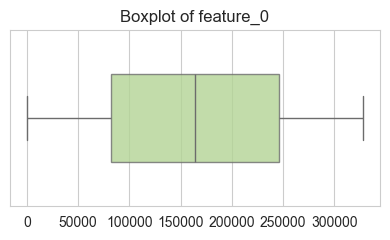

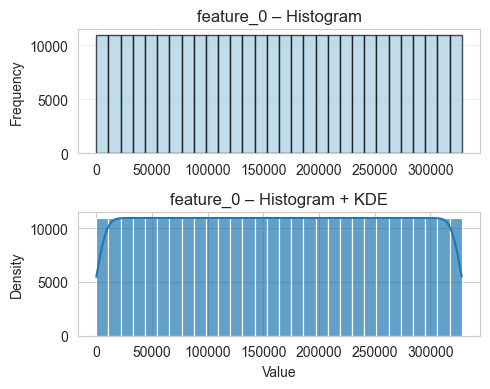

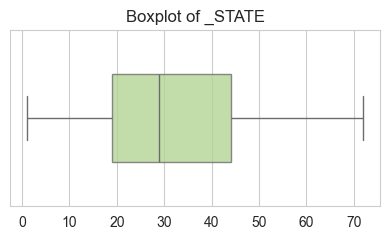

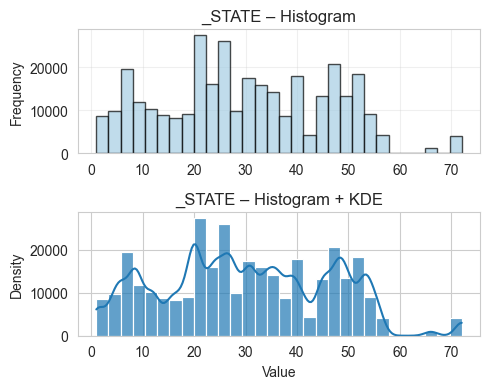

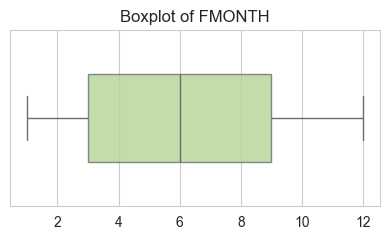

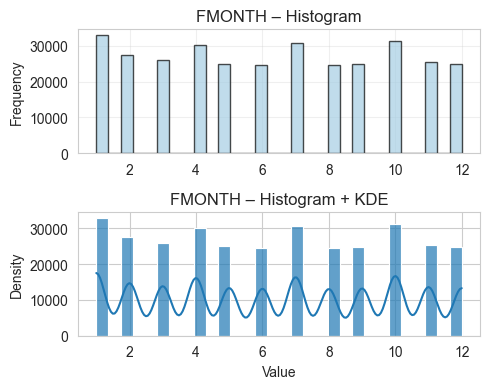

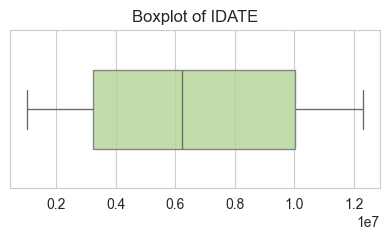

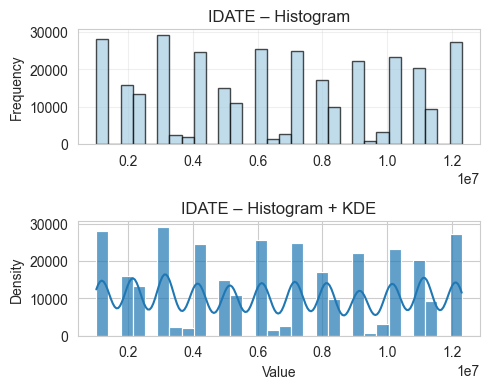

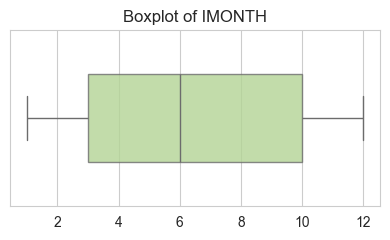

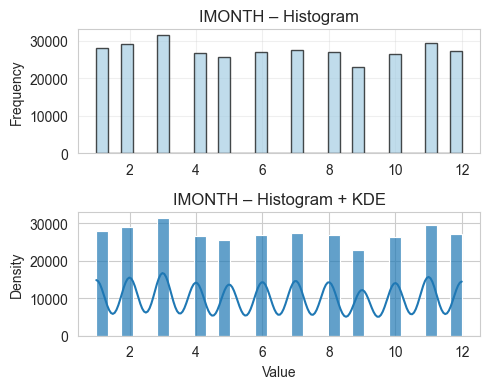

In [ ]:
n_features = x_train.shape[1]
n_show = 5  # show only first 5

# --- LOOP OVER FEATURES ---
for i in range(n_features):
    x = x_train[:, i]
    x = x[~np.isnan(x)]
    name = next((k for k, v in x_indices.items() if v == i), f"feature_{i}")

    # Skip constant features
    if np.nanstd(x) == 0 or len(x) < 2:
        continue

    # === 1. Boxplot ===
    plt.figure(figsize=(4, 2.5))
    sns.boxplot(x=x, color="#b2df8a", width=0.5, boxprops=dict(alpha=0.8))
    plt.title(f"Boxplot of {name}")
    plt.xlabel("")
    plt.tight_layout()

    box_path = os.path.join(box_dir_single, f"{name}_box.png")
    plt.savefig(box_path, bbox_inches="tight")
    if i < n_show:
        plt.show()
    else:
        plt.close()

    # === 2. Histogram + KDE (two subplots vertically) ===
    fig, axes = plt.subplots(2, 1, figsize=(5, 4))
    bins = 30

    # Histogram only
    axes[0].hist(x, bins=bins, color="#a6cee3", edgecolor="black", alpha=0.7)
    axes[0].set_title(f"{name} – Histogram")
    axes[0].set_ylabel("Frequency")
    axes[0].grid(alpha=0.3)

    # Histogram with KDE
    sns.histplot(x, bins=bins, kde=True, color="#1f78b4", alpha=0.7, ax=axes[1])
    axes[1].set_title(f"{name} – Histogram + KDE")
    axes[1].set_xlabel("Value")
    axes[1].set_ylabel("Density")

    plt.tight_layout()
    hist_path = os.path.join(hist_dir_single, f"{name}_hist_kde.png")
    plt.savefig(hist_path, bbox_inches="tight")
    if i < n_show:
        plt.show()
    else:
        plt.close()

print(f"\nSaved boxplots and histograms for all {n_features} features.")
print(f"Displayed first {n_show} features inline.")